c:\Users\Shubham\Desktop\SleepHealth-AI\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--- Generating SHAP Explainability Plot ---


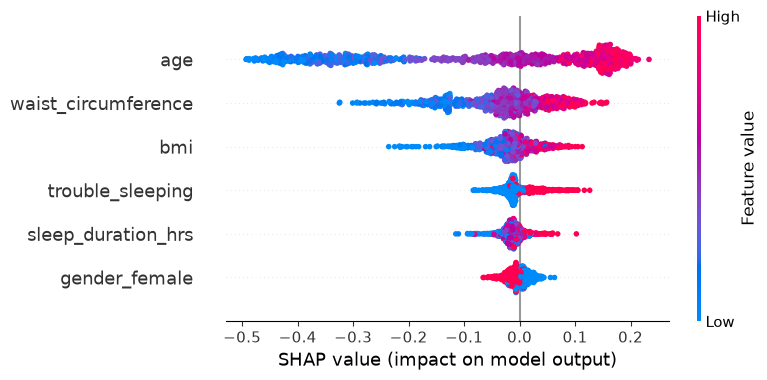

In [1]:
import pandas as pd
import joblib
import shap
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
warnings.filterwarnings('ignore')

print("--- Generating SHAP Explainability Plot ---")

# 1. Load the processed data and the winning Diabetes Model B
df = pd.read_csv('../data/processed/nhanes_processed.csv')
model = joblib.load('../models/diabetes_model.pkl')

features = ['age', 'gender_female', 'bmi', 'waist_circumference', 'sleep_duration_hrs', 'trouble_sleeping']
X = df[features]
y = df['target_diabetes']

# 2. Recreate the exact test set
_, X_test, _, _ = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Extract the fitted preprocessor and the Random Forest classifier
preprocessor = model[:-1] 
rf_classifier = model.named_steps['classifier']

# 4. Transform the test data (SHAP needs the raw numbers after imputation/scaling)
X_test_transformed = preprocessor.transform(X_test)

# 5. Initialize SHAP TreeExplainer
explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer.shap_values(X_test_transformed)

# 6. Handle SHAP version array differences for binary classification
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1] # Positive class (Diabetes)
elif len(shap_values.shape) == 3:
    shap_values_to_plot = shap_values[:, :, 1]
else:
    shap_values_to_plot = shap_values

# 7. Generate and display the SHAP Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_to_plot, X_test_transformed, feature_names=features, show=False)
plt.tight_layout()
plt.show()